# 07 · Stochastic interpolants, optimal transport and bridges

Connect endpoint coupling choices to path geometry, then add noise and distinguish an interpolant, an SDE and a Brownian bridge.

**Prerequisites:** 02–03; conditional expectation, continuity and Gaussian covariance.

**By the end:** Construct interpolant targets with derivatives; check equal-marginal fields; solve finite OT/Sinkhorn problems; simulate the joint Brownian bridge law; understand bridge-matching scope.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. A general stochastic interpolant

For an endpoint coupling $(X_s,X_d)\sim\pi$ and independent $Z\sim N(0,I)$,
$$I_\tau=a(\tau)X_s+b(\tau)X_d+\gamma(\tau)Z,$$
with $(a,b)=(1,0)$ at 0 and $(0,1)$ at 1, $\gamma(0)=\gamma(1)=0$.
Velocity regression targets $a'X_s+b'X_d+\gamma'Z$; its conditional average
is $v_\tau(x)$. Noise regression gives $s_\tau(x)=-\mathbb E[Z|I_\tau=x]/\gamma$ inside the interval.
For any nonnegative diffusion strength $e(\tau)$,
$$dX_\tau=[v_\tau+e s_\tau]d\tau+\sqrt{2e}\,dW_\tau$$
has the same continuity equation as $\dot X=v$, assuming exact fields and matching initial law.
This code uses $e=\kappa\gamma^2$ to avoid singular endpoint divisions in the learned drift.
**Code:** `StochasticInterpolant.targets`, `.learned_fields`, `GaussianInterpolantOracle` in [interpolants.py](../diffusion_lab/interpolants.py).

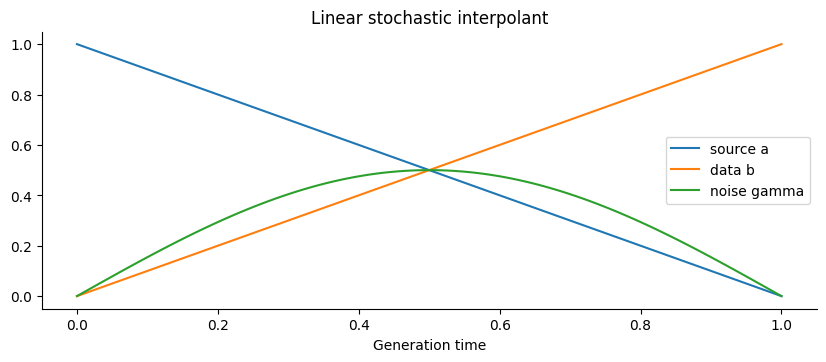

In [2]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.interpolants import GaussianInterpolantOracle, StochasticInterpolant
from diffusion_lab.paths import expand
from diffusion_lab.solvers import integrate

source_law = GaussianMixture(components=1, radius=0, std=1)
target_law = GaussianMixture(components=8, radius=3, std=0.3)
interpolant = StochasticInterpolant(path="linear", amplitude=0.5)
g = torch.Generator().manual_seed(101)
source, _ = source_law.sample(320, g)
target, _ = target_law.sample(320, g)
t = torch.rand(len(source), generator=g) * 0.98 + 0.01
state, velocity_target, noise = interpolant.targets(source, target, t, g)
a, b, gamma, da, db, dgamma = interpolant.coefficients(t)
torch.testing.assert_close(
    state, expand(a, source) * source + expand(b, target) * target + expand(gamma, noise) * noise
)
torch.testing.assert_close(
    velocity_target,
    expand(da, source) * source + expand(db, target) * target + expand(dgamma, noise) * noise,
)
grid = torch.linspace(0, 1, 100)
fig, ax = plt.subplots()
for values, label in zip(
    interpolant.coefficients(grid)[:3], ["source a", "data b", "noise gamma"], strict=True
):
    ax.plot(grid, values, label=label)
ax.set(xlabel="Generation time", title="Linear stochastic interpolant")
ax.legend()
plt.show()

## 2. Matching ODE/SDE marginals, different trajectories

The analytic oracle enumerates Gaussian endpoint components for **affine**
interpolants and computes marginal fields exactly. It cannot evaluate general
nonlinear endpoint paths. Use its ODE and SDE to isolate numerical/Monte Carlo error.
Each method below starts from the same actual source samples; SDE paths add Brownian noise.

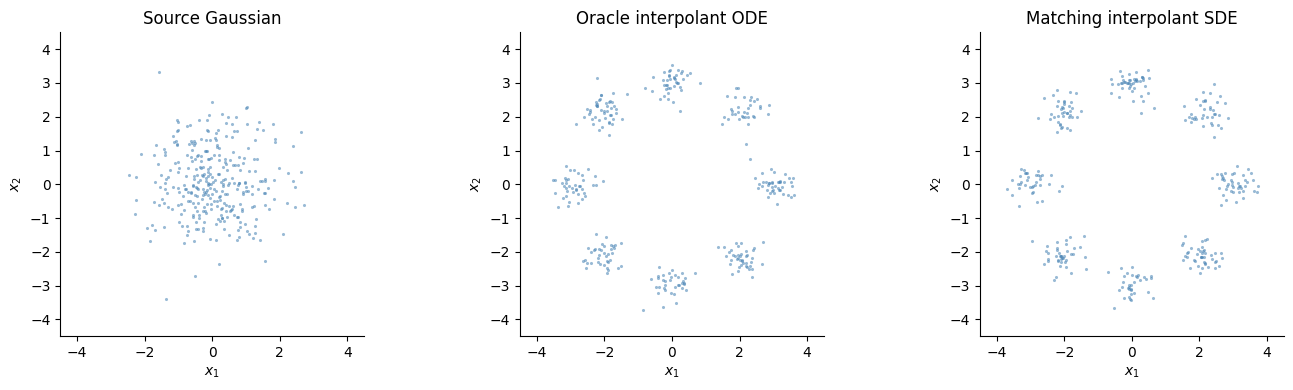

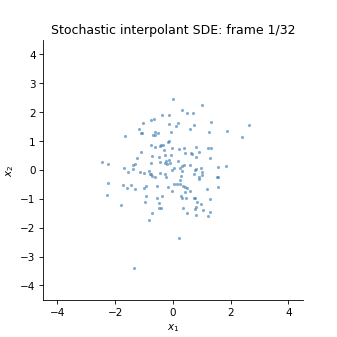

In [3]:
oracle = GaussianInterpolantOracle(source_law, target_law, interpolant)
times = torch.linspace(0, 1, 251)
ode, ode_history = integrate(lambda x, t: oracle.fields(x, t)[0], source, times, "heun")
sde, sde_history = integrate(
    lambda x, t: oracle.drift(x, t, strength=1),
    source,
    times,
    "euler_maruyama",
    lambda t: oracle.diffusion(t, strength=1),
    torch.Generator().manual_seed(102),
)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
scatter(axes[0], source, "Source Gaussian")
scatter(axes[1], ode, "Oracle interpolant ODE")
scatter(axes[2], sde, "Matching interpolant SDE")
plt.tight_layout()
plt.show()
animate_particles(sde_history[:, :150], "07_stochastic_interpolant", "Stochastic interpolant SDE")

## 3. Nonlinear paths need the correct derivative

A custom $I(\tau,x_s,x_d)$ can bend endpoint-pair curves while preserving
endpoints. `targets` uses a Jacobian-vector product in time; manually keeping
the linear target after changing the path would supervise the wrong velocity.
The example is a hand-designed nonlinear path, **not a learned optimized path**.

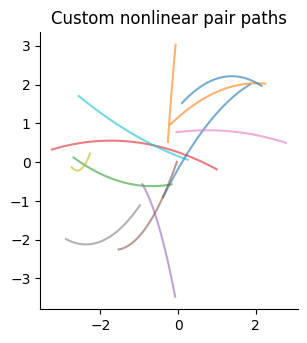

In [4]:
def nonlinear_base(source, target, t):
    time = t[:, None]
    bend = torch.stack([torch.zeros_like(t), torch.sin((target - source)[:, 0])], dim=1)
    return (1 - time) * source + time * target + 2 * time * (1 - time) * bend


nonlinear = StochasticInterpolant(amplitude=0.2, base_fn=nonlinear_base)
torch.testing.assert_close(nonlinear_base(source, target, torch.zeros(len(source))), source)
torch.testing.assert_close(nonlinear_base(source, target, torch.ones(len(source))), target)
state, velocity, noise = nonlinear.targets(source, target, t, torch.Generator().manual_seed(103))
h = 1e-3
finite_difference = (
    nonlinear_base(source, target, t + h) - nonlinear_base(source, target, t - h)
) / (2 * h)
dgamma = nonlinear.coefficients(t)[-1]
torch.testing.assert_close(
    velocity - expand(dgamma, noise) * noise, finite_difference, atol=6e-4, rtol=6e-4
)
fig, ax = plt.subplots()
curves = torch.stack(
    [nonlinear_base(source[:12], target[:12], time.repeat(12)) for time in torch.linspace(0, 1, 50)]
)
ax.plot(curves[:, :, 0], curves[:, :, 1], alpha=0.6)
ax.set(title="Custom nonlinear pair paths", aspect="equal")
plt.show()

## 4. Exact empirical OT versus entropic OT

For uniform finite endpoints and $C_{ij}=\|x_i-y_j\|^2/2$,
exact OT minimizes $\langle\pi,C\rangle$ subject to uniform marginals.
Equal counts admit a permutation/Hungarian assignment.
Sinkhorn minimizes $\langle\pi,C\rangle+\varepsilon KL(\pi\|a\otimes b)$.
Larger $\varepsilon$ generally spreads the coupling. It trades transport cost
against entropy; entropy-regularized cost is not unregularized Wasserstein distance.
Minibatch OT is a finite empirical choice, not proof of population-optimal learned transport.
**Code:** `exact_pairing`, `sinkhorn_plan`, `sample_coupling` in [transport.py](../diffusion_lab/transport.py).

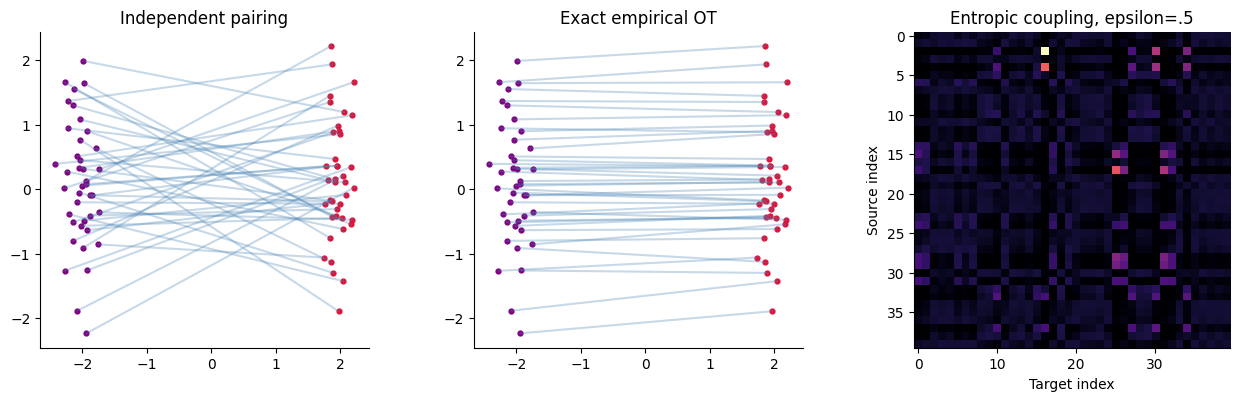

Independent / exact / entropic transport costs: 8.866312026977539 8.010236740112305 8.225177764892578


In [5]:
from diffusion_lab.transport import exact_pairing, sample_coupling, sinkhorn_plan

g = torch.Generator().manual_seed(104)
left = torch.randn(40, 2, generator=g) * torch.tensor([0.15, 1.0]) + torch.tensor([-2.0, 0.0])
right = torch.randn(40, 2, generator=g) * torch.tensor([0.15, 1.0]) + torch.tensor([2.0, 0.0])
paired = exact_pairing(left, right)
cost = torch.cdist(left, right).square() / 2
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, endpoints, title in [
    (axes[0], right, "Independent pairing"),
    (axes[1], paired, "Exact empirical OT"),
]:
    for a, b in zip(left, endpoints, strict=True):
        ax.plot([a[0], b[0]], [a[1], b[1]], alpha=0.3, color="steelblue")
    ax.scatter(*left.T, c="purple", s=12)
    ax.scatter(*right.T, c="crimson", s=12)
    ax.set(title=title, aspect="equal")
plan = sinkhorn_plan(left, right, epsilon=0.5, iterations=3000)
axes[2].imshow(plan, cmap="magma")
axes[2].set(title="Entropic coupling, epsilon=.5", xlabel="Target index", ylabel="Source index")
plt.tight_layout()
plt.show()
torch.testing.assert_close(plan.sum(1), torch.full((40,), 1 / 40), atol=1e-6, rtol=1e-6)
torch.testing.assert_close(plan.sum(0), torch.full((40,), 1 / 40), atol=1e-6, rtol=1e-6)
print(
    "Independent / exact / entropic transport costs:",
    (left - right).square().sum(1).mean().item() / 2,
    (left - paired).square().sum(1).mean().item() / 2,
    (plan * cost).sum().item(),
)

## 5. Brownian bridges and the Schrödinger connection

For Brownian-reference variance rate $\varepsilon$ over unit time,
the conditional bridge between endpoints is
$$X_\tau=(1-\tau)x_s+\tau x_d+\sqrt\varepsilon(W_\tau-\tau W_1).$$
Its covariance is $\varepsilon(\min(s,t)-st)I$. At one time this gives noise
standard deviation $\sqrt{\varepsilon\tau(1-\tau)}$, but independent redraws of
this noise would not give the joint bridge law.
The conditional forward drift is $(x_d-x)/(1-\tau)$; bridge matching regresses
it and averages over endpoint posteriors to obtain a Markov drift.
For Brownian reference the endpoint kernel is $e^{-C/\varepsilon}$, explaining
the entropic-OT connection. Continuous Schrödinger bridges minimize path-space
KL to a reference process subject to endpoint marginals.
Our finite atomic endpoint construction uses a discrete kernel: it is not
a finite path-KL claim against unrestricted Wiener measure with atomic endpoints.
**Code:** [bridges.py](../diffusion_lab/bridges.py), [iterative neural projections](../diffusion_lab/dsbm.py).

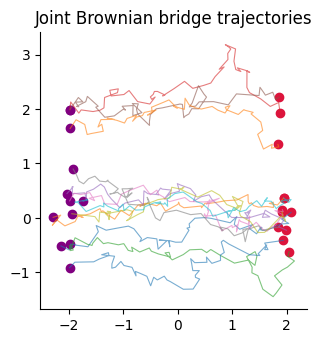

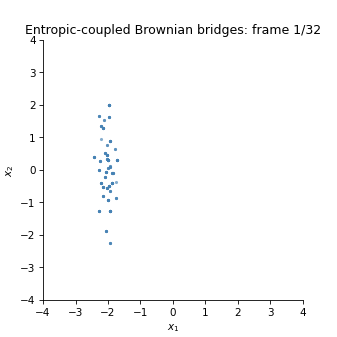

Covariance at times .3/.7, empirical / analytic: 0.04679780825972557 0.045


In [6]:
from diffusion_lab.bridges import bridge_training_pair, brownian_bridge_trajectory

bridge_source, bridge_target = sample_coupling(
    left, right, plan, 180, torch.Generator().manual_seed(105)
)
times = torch.linspace(0, 1, 51)
trajectory = brownian_bridge_trajectory(
    bridge_source, bridge_target, times, epsilon=0.5, generator=torch.Generator().manual_seed(106)
)
torch.testing.assert_close(trajectory[0], bridge_source)
torch.testing.assert_close(trajectory[-1], bridge_target, atol=1e-6, rtol=1e-6)
fig, ax = plt.subplots()
ax.plot(trajectory[:, :12, 0], trajectory[:, :12, 1], alpha=0.6, linewidth=0.8)
ax.scatter(*bridge_source[:12].T, c="purple")
ax.scatter(*bridge_target[:12].T, c="crimson")
ax.set(title="Joint Brownian bridge trajectories", aspect="equal")
plt.show()
animate_particles(
    trajectory, "07_brownian_bridges", "Entropic-coupled Brownian bridges", limits=(-4, 4)
)
zeros = torch.zeros(8000, 2)
bridge_noise = brownian_bridge_trajectory(
    zeros,
    zeros,
    torch.linspace(0, 1, 11),
    epsilon=0.5,
    generator=torch.Generator().manual_seed(107),
)
empirical = (bridge_noise[3, :, 0] * bridge_noise[7, :, 0]).mean().item()
expected = 0.5 * (0.3 - 0.3 * 0.7)
print("Covariance at times .3/.7, empirical / analytic:", empirical, expected)
assert abs(empirical - expected) < 0.006

In [7]:
time = torch.full((len(bridge_source),), 0.4)
state, drift, velocity = bridge_training_pair(bridge_source, bridge_target, time, 0.5)
assert state.shape == drift.shape == velocity.shape == bridge_source.shape
print("Drift vs continuity velocity RMSE:", (drift - velocity).square().mean().sqrt().item())

Drift vs continuity velocity RMSE: 0.6610203981399536


## Exercises and worked answers

1. Show that drift $v+es$ and diffusion $\sqrt{2e}$ cancel their score/Laplacian contributions in Fokker–Planck.
2. Why should exact OT pairing be restricted within classes when preserving a class-independent noise prior?
3. Explain why a conditional bridge drift and a continuity velocity are different targets.

<details><summary>Worked answers</summary>

1. $-\nabla\cdot(esp)+e\Delta p=0$ because $sp=\nabla p$ and $e$ depends only on time.
2. Global assignment can make the paired noise distribution conditional on data geometry/class; class-wise matching preserves each empirical class's source-noise marginal.
3. Markov diffusion drift includes probability current plus a score contribution. For variance rate $\varepsilon$, continuity velocity is drift $-\varepsilon s/2$.

</details>

**Animations:** [Interpolant SDE](../assets/teaching/notebooks/07_stochastic_interpolant.gif), [bridges](../assets/teaching/notebooks/07_brownian_bridges.gif).
**Research extensions:** [Interpolant scope](../docs/17_stochastic_interpolants.md), [bridges](../docs/06_bridges.md), [iterative matching](../docs/11_iterative_bridges.md).
**Continue:** [EDM and consistency](08_edm_and_few_step_models.ipynb).
**Sources:** [Stochastic interpolants](https://arxiv.org/abs/2303.08797), [Sinkhorn](https://arxiv.org/abs/1306.0895), [DSBM](https://arxiv.org/abs/2303.16852).